# Cleaning der Herzfrequenzdaten

Dieses Notebook lädt die zusammengeführten Fitnessdaten (`merged_data.csv`) und 
untersucht fehlende Werte in der Spalte `heart_rate`. Ziel ist es, Lücken 
nachvollziehbar zu behandeln (Interpolation oder bewusstes Belassen von NaN), 
bevor die Daten für die weitere Analyse verwendet werden.

**Vorgehen:**
1. Überblick über den Anteil fehlender Werte pro Fahrt (`source_file`)
2. Fahrten ohne Herzfrequenzsensor (100% NaN) werden identifiziert und ignoriert
3. Fahrten mit teilweise fehlenden Werten werden einzeln untersucht
4. Je nach Kontext (Leistung, Dauer der Lücke, Position im Herzfrequenzbereich) 
   wird linear interpoliert oder die Lücke bewusst als NaN belassen

**Output:**

Als Ergebnis dieses Notebooks entsteht `processed_data.csv` – eine bereinigte Version der Fitnessdaten mit denselben Spalten wie `merged_data.csv` (u.a. `timestamp`, `source_file`, `heart_rate`, `power`).

Diese Datei dient als Ausgangspunkt für die anschließende Datenanalyse.

In [1]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from datetime import datetime, timedelta

In [2]:
df = pd.read_csv("./Dataframes/merged_data.csv", encoding="utf-8", parse_dates=["timestamp"], index_col = 'timestamp')

In [3]:
summary = df.groupby("source_file")["heart_rate"].agg(
    total="size",
    nan_count=lambda x: x.isna().sum()
)
summary["nan_ratio"] = summary["nan_count"] / summary["total"]
summary

,total,nan_count,nan_ratio
source_file,,,
2026-01-10-13-32-12.fit,971,971,1.0
2026-01-10-13-59-21.fit,5375,5375,1.0
2026-01-10-17-37-48.fit,1274,1274,1.0
2026-01-11-11-16-39.fit,1314,1314,1.0
2026-01-11-12-00-28.fit,1848,1848,1.0
...,...,...,...
2026-10-10-15-50-43.fit,977,0,0.0
2026-10-10-16-08-26.fit,2980,0,0.0
2026-10-12-19-45-31.fit,2623,0,0.0


Bei Fahrten ohne Herzfrequenzdaten habe ich keinen Herzfrequenzmesser getragen. Hier kann ich nichts interpolieren. Interessanter sind Fahrten mit **teilweise** fehlenden Werten (`0 < nan_ratio < 1`), 
da hier ein Sensor grundsätzlich verbunden war und die Lücke wahrscheinlich durch 
eine kurzzeitige Verbindungsunterbrechung entstanden ist. Diese Fahrten schauen 
wir uns im Folgenden einzeln an.

In [4]:
rides_with_some_missing_values = summary[(summary.nan_ratio > 0) & (summary.nan_ratio < 1)]
rides_with_some_missing_values

,total,nan_count,nan_ratio
source_file,,,
2026-01-31-13-35-38.fit,6118,62,0.010134
2026-02-15-14-57-18.fit,4996,8,0.001601
2026-02-19-14-18-09.fit,8257,28,0.003391
2026-02-20-14-16-55.fit,8146,102,0.012521
2026-02-26-20-51-14.fit,3310,597,0.180363
2026-05-17-20-02-35.fit,4433,39,0.008798
2026-06-03-15-30-13.fit,7005,7,0.000999
2026-06-17-15-49-01.fit,6080,378,0.062171
2026-07-11-14-54-53.fit,7226,11,0.001522


In [5]:
ride_with_missing_values = df.loc[(df.source_file == "2026-02-15-14-57-18.fit") & (df.heart_rate.isna()), ["heart_rate", "power"]]
ride_with_missing_values

,heart_rate,power
timestamp,,
2026-02-15 14:53:02+00:00,NaN,0
2026-02-15 14:53:03+00:00,NaN,0
2026-02-15 14:53:04+00:00,NaN,0
2026-02-15 14:53:05+00:00,NaN,0
2026-02-15 14:53:06+00:00,NaN,0
2026-02-15 14:53:07+00:00,NaN,0
2026-02-15 14:53:08+00:00,NaN,0
2026-02-15 14:53:09+00:00,NaN,0


Das ist ein Zeitintervall ohne Unterbrechung. Schauen wir es uns mit den Werten davor und danach an.

In [6]:
def plot_power_and_heart_rate(
    df: pd.DataFrame,
    start_time: datetime,
    end_time: datetime
) -> None:
    """Plot power and heart rate for a given time range using dual y-axes.

    Args:
        df: DataFrame containing 'power' and 'heart_rate' columns with datetime index.
        start_time: Start datetime of the range (inclusive).
        end_time: End datetime of the range (inclusive).
    """
    # Filter data based on datetime range
    mask = (df.index >= start_time - timedelta(seconds=30)) & (df.index <= end_time + timedelta(seconds=30))
    subset = df.loc[mask]

    # Create figure with dual y-axes
    fig = go.Figure()

    # Add power trace (left y-axis)
    fig.add_trace(go.Scatter(
        x=subset.index,
        y=subset["power"],
        name="Power",
        mode="lines+markers",
        yaxis="y1"
    ))

    # Add heart rate trace (right y-axis)
    fig.add_trace(go.Scatter(
        x=subset.index,
        y=subset["heart_rate"],
        name="Heart Rate",
        mode="lines+markers",
        yaxis="y2"
    ))

    # Configure layout with dual axes
    fig.update_layout(
        title="Power and Heart Rate Over Time",
        xaxis_title="Time",
        yaxis=dict(title="Power (W)", side="left"),
        yaxis2=dict(title="Heart Rate (bpm)", side="right", overlaying="y"),
        legend=dict(x=0.01, y=1.1, orientation="h")
    )

    fig.show()

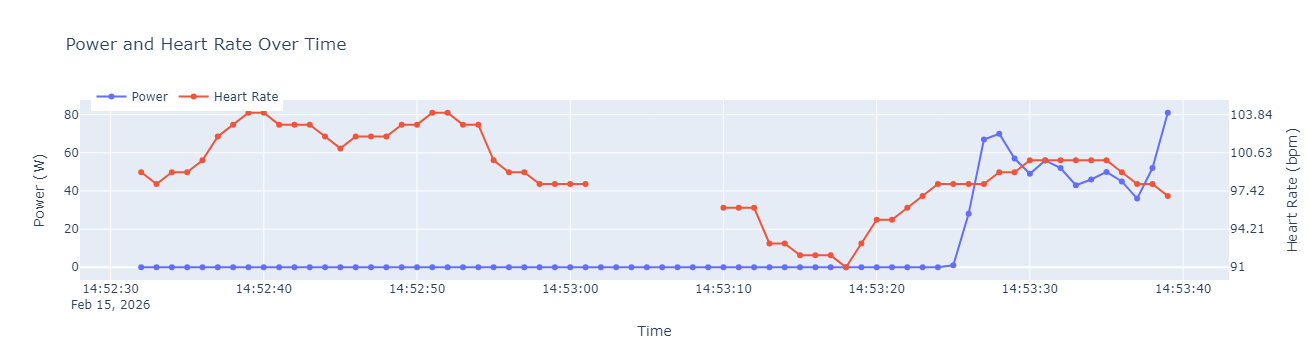

In [7]:
plot_power_and_heart_rate(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())

In [8]:
def interpolate_range(df: pd.DataFrame, start_time: datetime, end_time: datetime) -> pd.DataFrame:
    """Linearly interpolate NaN values in a column between two indices (inclusive) and round to int.

    Args:
        df: DataFrame containing the column to interpolate.
        column: Name of the column to interpolate.
        start_time: Start datetime of the range (inclusive).
        end_time: End datetime of the range (inclusive).

    Returns:
        The modified DataFrame (interpolation applied in place).
    """
    mask = (df.index >= start_time - timedelta(seconds=1)) & (df.index <= end_time + timedelta(seconds=1))
    df.loc[mask, 'heart_rate'] = df.loc[mask, 'heart_rate'].interpolate(method="linear").round()
    return df

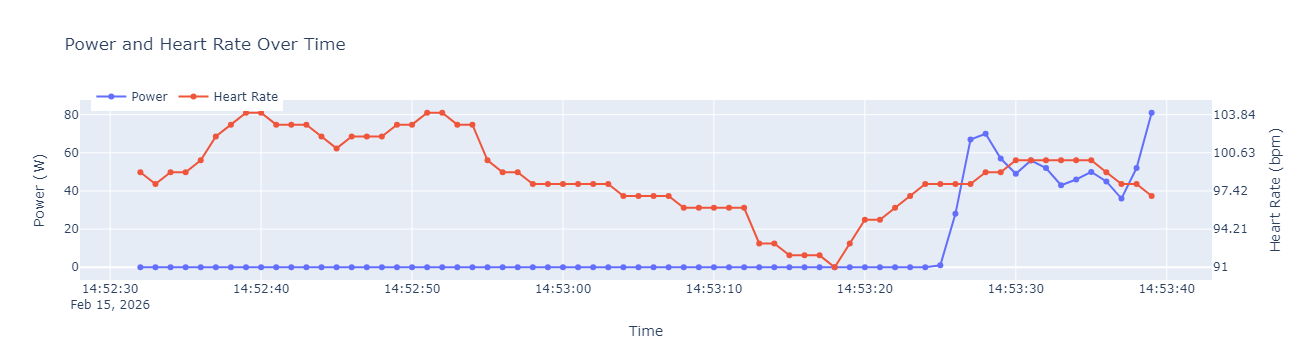

In [9]:
df = interpolate_range(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())
plot_power_and_heart_rate(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())

In [10]:
ride_with_missing_values = df.loc[(df.source_file == "2026-06-03-15-30-13.fit") & (df.heart_rate.isna()), ["heart_rate", "power"]]
print(ride_with_missing_values)

                           heart_rate  power
timestamp                                   
2026-06-03 14:57:30+00:00         NaN     27
2026-06-03 14:57:31+00:00         NaN     27
2026-06-03 14:57:32+00:00         NaN      0
2026-06-03 14:57:33+00:00         NaN      0
2026-06-03 14:57:34+00:00         NaN      0
2026-06-03 14:57:35+00:00         NaN      0
2026-06-03 14:57:36+00:00         NaN      0


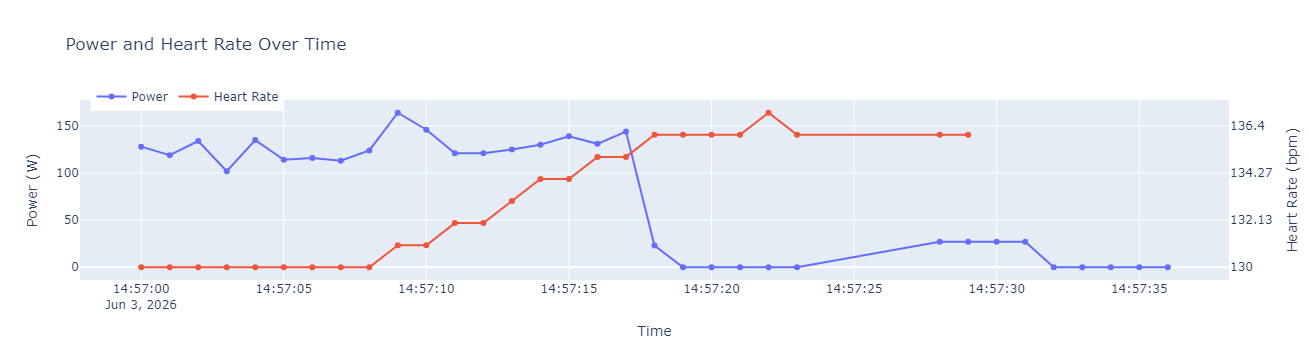

In [11]:
plot_power_and_heart_rate(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())

In [12]:
df[df.index >= "2026-06-03 14:57:36+00:00"].head()

,source_file,cadence,enhanced_speed,heart_rate,power,target_power,MESS_DATUM,TT_10,PP_10,RF_10,timestamp_berlin,day_of_week,month,hour_utc,hour_berlin,time_of_day
timestamp,,,,,,,,,,,,,,,,
2026-06-03 14:57:36+00:00,2026-06-03-15-30-13.fit,0,0.000,NaN,0,NaN,2026-06-03 15:00:00+00:00,14.7,952.7,80.3,2026-06-03 16:57:36+02:00,Wednesday,June,14,16,Afternoon
2026-06-03 14:58:19+00:00,2026-06-03-15-30-13.fit,1,0.017,127.0,72,NaN,2026-06-03 15:00:00+00:00,14.7,952.7,80.3,2026-06-03 16:58:19+02:00,Wednesday,June,14,16,Afternoon
2026-06-03 14:58:20+00:00,2026-06-03-15-30-13.fit,1,0.324,127.0,72,NaN,2026-06-03 15:00:00+00:00,14.7,952.7,80.3,2026-06-03 16:58:20+02:00,Wednesday,June,14,16,Afternoon
2026-06-03 14:58:21+00:00,2026-06-03-15-30-13.fit,1,0.997,127.0,148,NaN,2026-06-03 15:00:00+00:00,14.7,952.7,80.3,2026-06-03 16:58:21+02:00,Wednesday,June,14,16,Afternoon
2026-06-03 14:58:22+00:00,2026-06-03-15-30-13.fit,53,1.329,127.0,116,NaN,2026-06-03 15:00:00+00:00,14.7,952.7,80.3,2026-06-03 16:58:22+02:00,Wednesday,June,14,16,Afternoon


In [13]:
ride_with_missing_values = df.loc[(df.source_file == "2026-07-11-14-54-53.fit") & (df.heart_rate.isna()), ["heart_rate", "power"]]
print(ride_with_missing_values)

                           heart_rate  power
timestamp                                   
2026-07-11 14:24:04+00:00         NaN      0
2026-07-11 14:24:05+00:00         NaN      0
2026-07-11 14:24:06+00:00         NaN      0
2026-07-11 14:24:07+00:00         NaN      0
2026-07-11 14:24:08+00:00         NaN      0
2026-07-11 14:24:09+00:00         NaN      0
2026-07-11 14:24:10+00:00         NaN      0
2026-07-11 14:24:11+00:00         NaN      0
2026-07-11 14:24:12+00:00         NaN      0
2026-07-11 14:24:13+00:00         NaN      0
2026-07-11 14:24:14+00:00         NaN      0


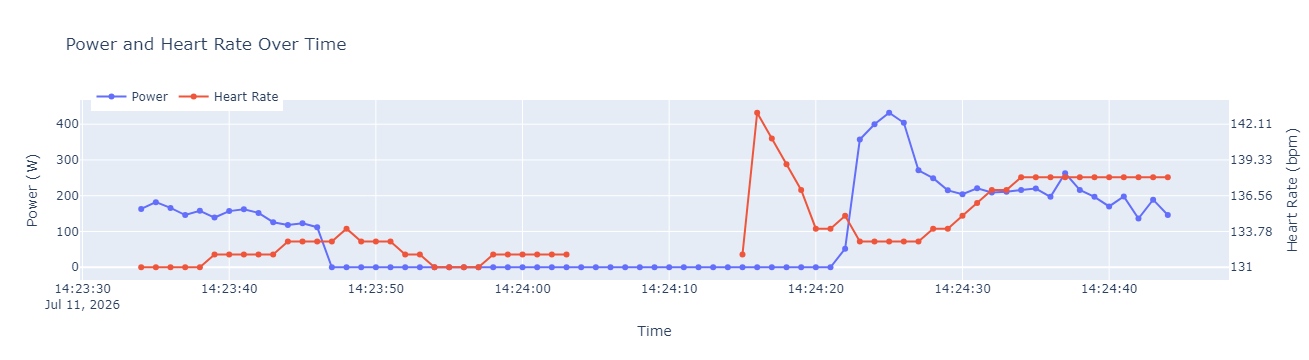

In [14]:
plot_power_and_heart_rate(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())

Hier kann ich in den Daten keine Erklärung für den Herzfrequenz-Spike nach den fehlenden Werten entdecken. Es könnte sein, dass irgendetwas passiert ist, was die Daten nicht abbilden (z.B. ich bin schnell abgestiegen und habe einen Energieriegel geholt). Ich würde die Daten daher trotzdem linear annähern.

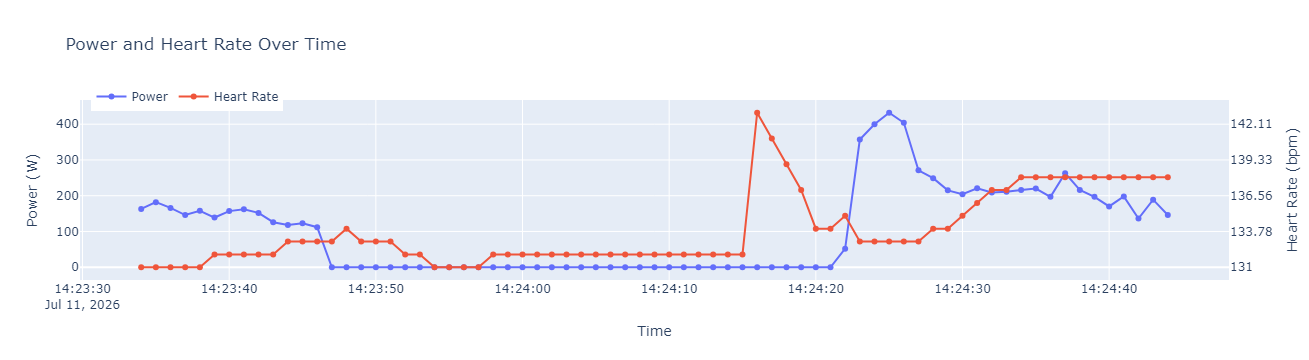

In [15]:
df = interpolate_range(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())
plot_power_and_heart_rate(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())

In [16]:
ride_with_missing_values = df.loc[(df.source_file == "2026-02-19-14-18-09.fit") & (df.heart_rate.isna()), ["heart_rate", "power"]]

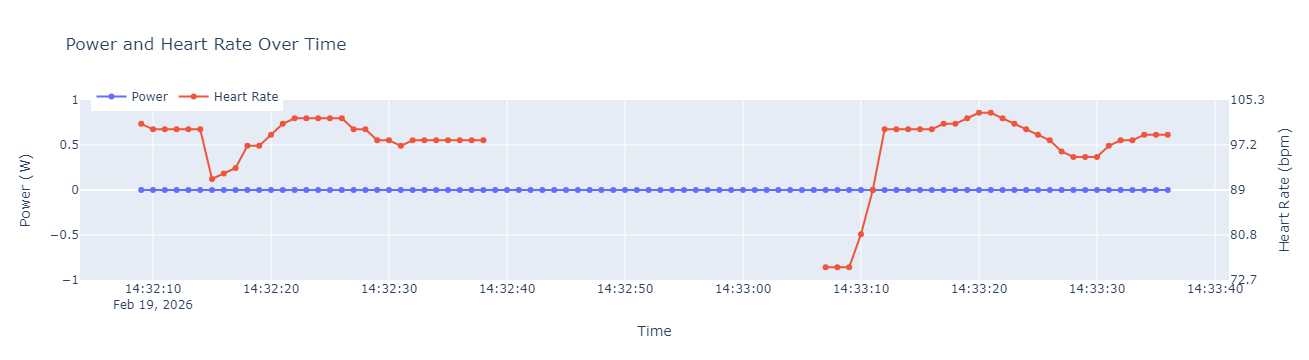

In [17]:
plot_power_and_heart_rate(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())

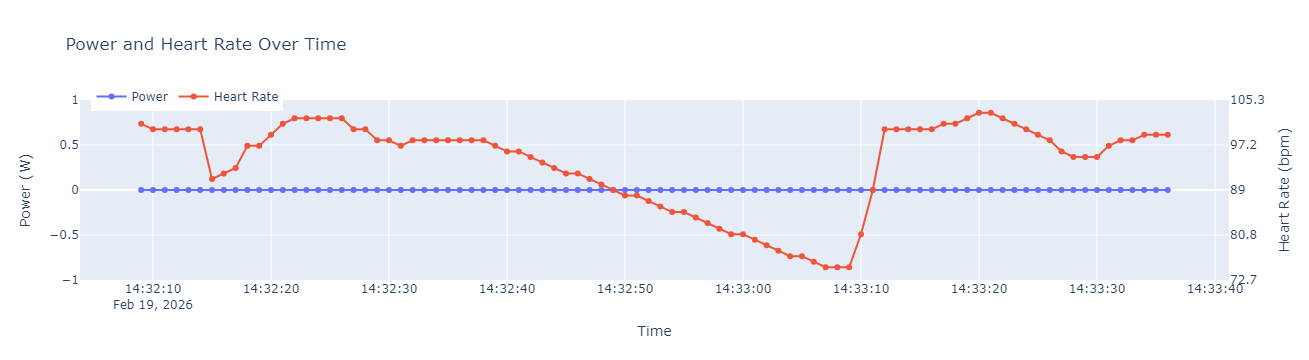

In [18]:
interpolate_range(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())
plot_power_and_heart_rate(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())

In [19]:
ride_with_missing_values = df.loc[(df.source_file == "2026-05-17-20-02-35.fit") & (df.heart_rate.isna()), ["heart_rate", "power"]]

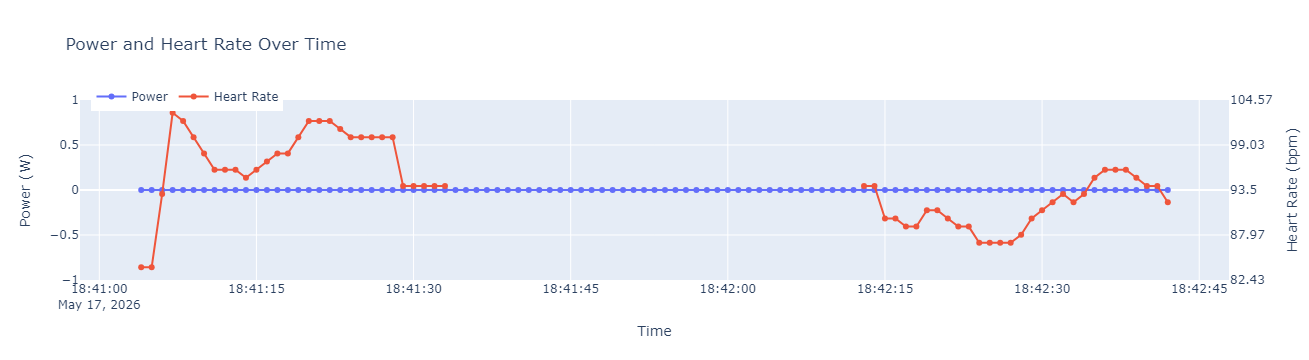

In [20]:
plot_power_and_heart_rate(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())

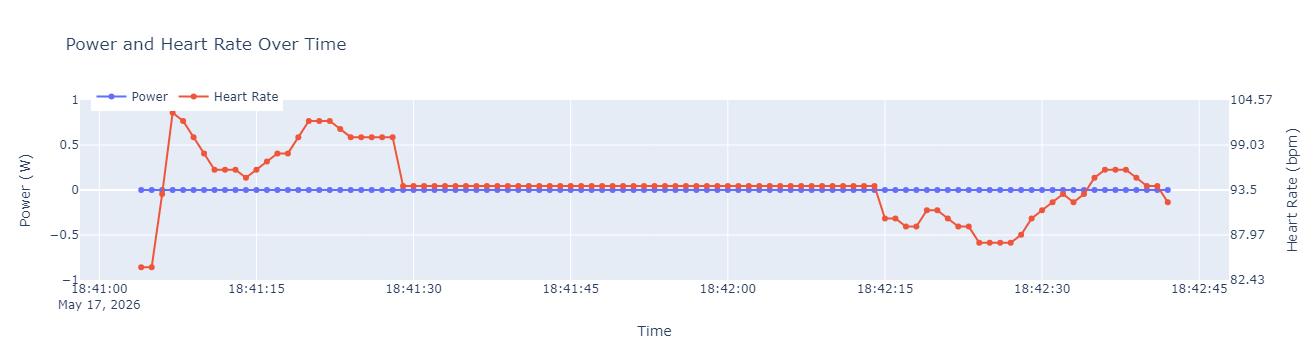

In [21]:
interpolate_range(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())
plot_power_and_heart_rate(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())

In [22]:
ride_with_missing_values = df.loc[(df.source_file == "2026-01-31-13-35-38.fit") & (df.heart_rate.isna()), ["heart_rate", "power"]]

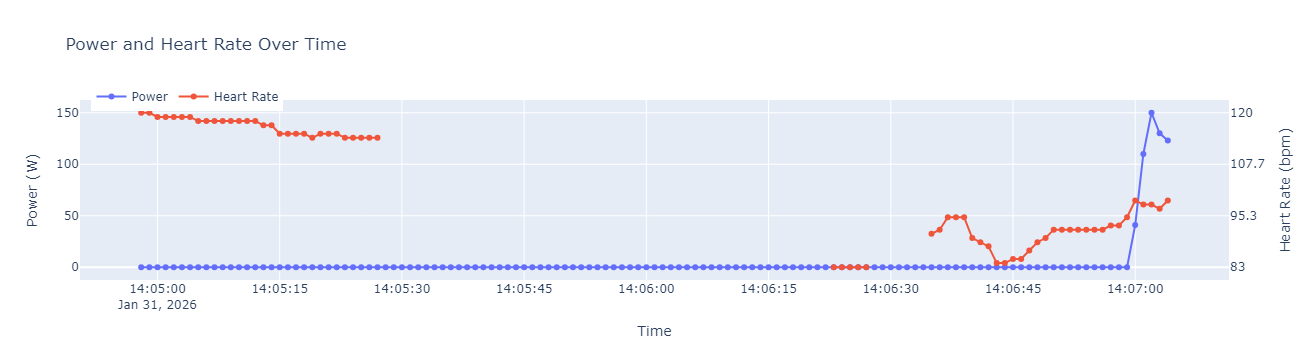

In [23]:
plot_power_and_heart_rate(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())

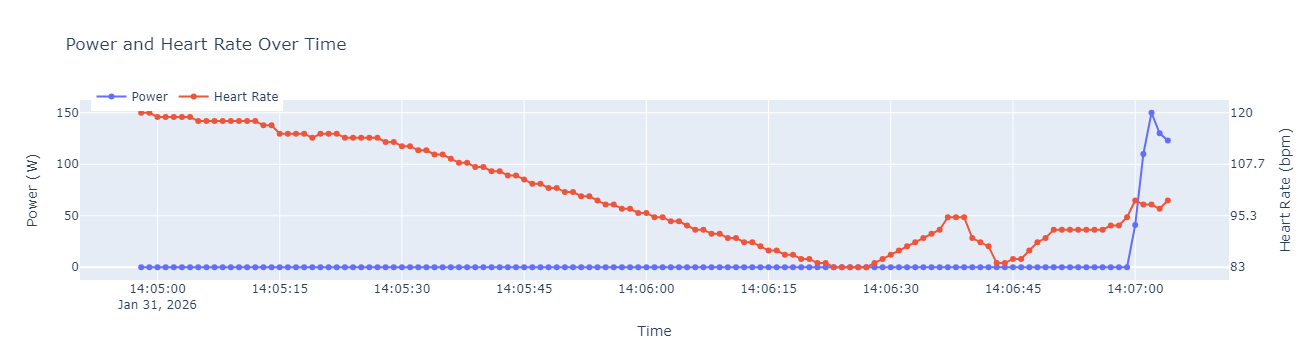

In [24]:
df = interpolate_range(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())
plot_power_and_heart_rate(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())

In [25]:
summary = df.groupby("source_file")["heart_rate"].agg(
    total="size",
    nan_count=lambda x: x.isna().sum()
)
summary["nan_ratio"] = summary["nan_count"] / summary["total"]

summary[(summary.nan_ratio > 0) & (summary.nan_ratio < 1)]

,total,nan_count,nan_ratio
source_file,,,
2026-02-20-14-16-55.fit,8146,102,0.012521
2026-02-26-20-51-14.fit,3310,597,0.180363
2026-06-03-15-30-13.fit,7005,7,0.000999
2026-06-17-15-49-01.fit,6080,378,0.062171
2026-08-27-19-58-44.fit,2769,6,0.002167
2026-09-20-14-01-24.fit,7454,12,0.001610


In [26]:
ride_with_missing_values = df.loc[(df.source_file == "2026-02-20-14-16-55.fit") & (df.heart_rate.isna()), ["heart_rate", "power"]]

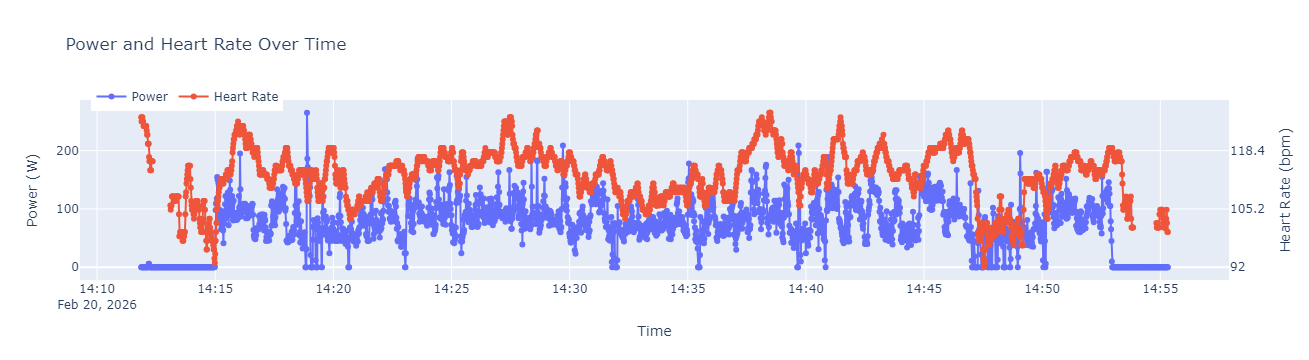

In [27]:
plot_power_and_heart_rate(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())

Da diese Fahrt offenbar mehrere Lücken enthält, reicht eine einfache Betrachtung 
der NaN-Zeilen nicht mehr aus. Wir definieren daher zwei Hilfsfunktionen:

- `plot_missing_heatmap`: visualisiert, wo genau in der Fahrt Werte fehlen
- `get_missing_intervals`: extrahiert die einzelnen zusammenhängenden Lücken 
  (Start, Ende, Länge) als Tabelle

In [28]:
def plot_missing_heatmap(
    df: pd.DataFrame,
    start_time: pd.Timestamp | None = None,
    end_time: pd.Timestamp | None = None,
) -> go.Figure:
    """Plot a heatmap showing where heart_rate values are missing.

    Args:
        df: DataFrame with a DatetimeIndex and a 'heart_rate' column.
        start_time: Optional start of the time range to display.
        end_time: Optional end of the time range to display.

    Returns:
        A Plotly figure showing missing vs. present values over time.
    """
    subset = df.loc[start_time:end_time]

    missing_flags = subset[["heart_rate"]].isna().astype(int).T

    fig = px.imshow(
        missing_flags,
        x=subset.index,
        y=["heart_rate"],
        color_continuous_scale=["seagreen", "crimson"],
        labels={"x": "Zeit", "color": "Fehlt"},
        title="Fehlende Werte in 'heart_rate'",
    )

    fig.update_layout(height=250)

    return fig

In [29]:
def get_missing_intervals(
    df: pd.DataFrame,
    start_time: pd.Timestamp | None = None,
    end_time: pd.Timestamp | None = None,
) -> pd.DataFrame:
    """Extract intervals of consecutive missing heart_rate values.

    Args:
        df: DataFrame with a DatetimeIndex and a 'heart_rate' column.
        start_time: Optional start of the time range to consider.
        end_time: Optional end of the time range to consider.

    Returns:
        A DataFrame with columns 'start', 'end', and 'count' for each gap.
    """
    subset = df.loc[start_time:end_time]

    is_missing = subset["heart_rate"].isna()
    group_ids = is_missing.ne(is_missing.shift()).cumsum()

    gaps = (
        subset[is_missing]
        .groupby(group_ids[is_missing])
        .agg(
            start=("heart_rate", lambda x: x.index.min()),
            end=("heart_rate", lambda x: x.index.max()),
            count=("heart_rate", "size"),
        )
        .reset_index(drop=True)
    )

    return gaps

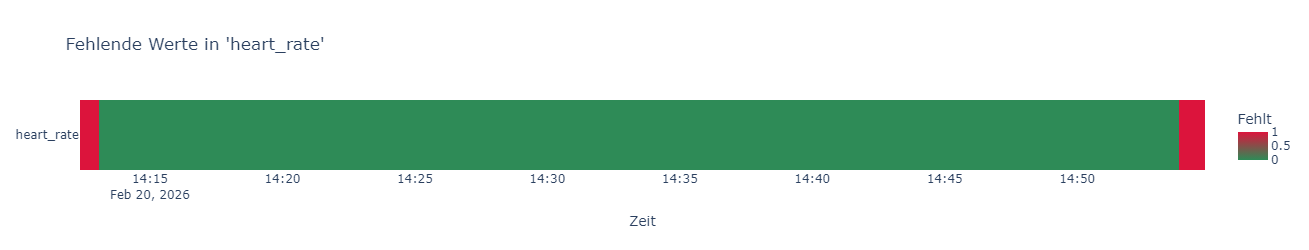

In [30]:
plot_missing_heatmap(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())

In [31]:
missing_intervals = get_missing_intervals(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())
print(missing_intervals)

                      start                       end  count
0 2026-02-20 14:12:22+00:00 2026-02-20 14:13:05+00:00     44
1 2026-02-20 14:53:52+00:00 2026-02-20 14:54:49+00:00     58


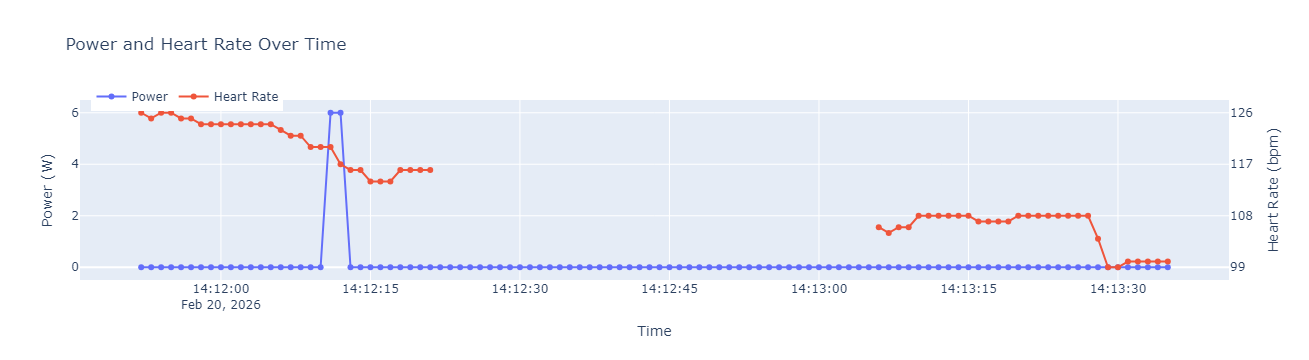

In [32]:
plot_power_and_heart_rate(df, missing_intervals.start[0], missing_intervals.end[0])

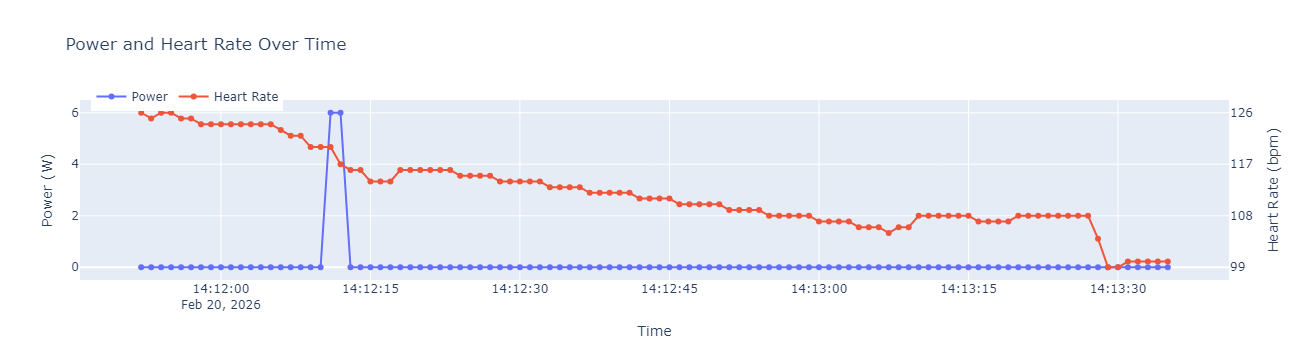

In [33]:
df = interpolate_range(df, missing_intervals.start[0], missing_intervals.end[0])
plot_power_and_heart_rate(df, missing_intervals.start[0], missing_intervals.end[0])

Nun das zweite Intervall:

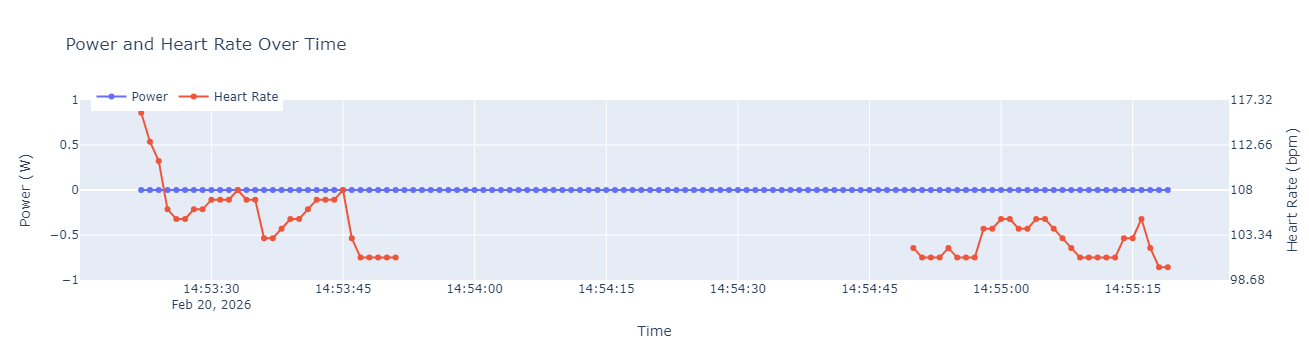

In [34]:
plot_power_and_heart_rate(df, missing_intervals.start[1], missing_intervals.end[1])

Wieder linear:

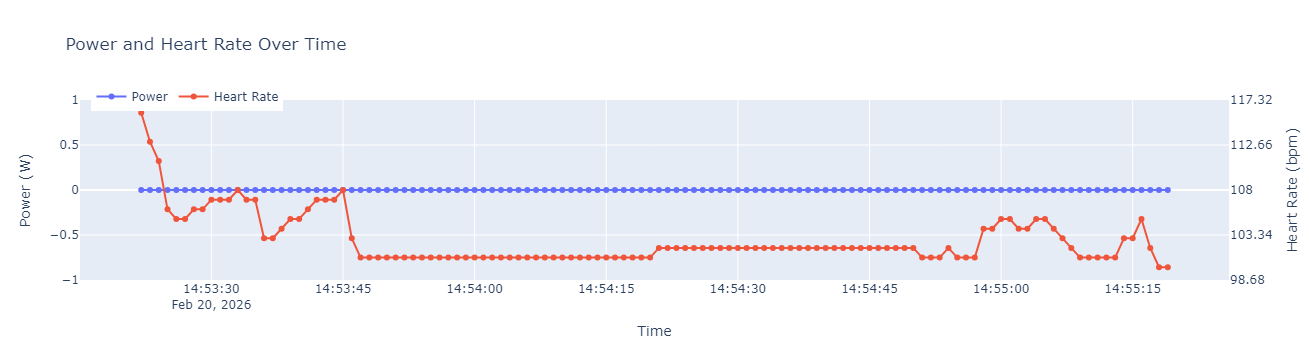

In [35]:
df = interpolate_range(df, missing_intervals.start[1], missing_intervals.end[1])
plot_power_and_heart_rate(df, missing_intervals.start[1], missing_intervals.end[1])

In [36]:
ride_with_missing_values = df.loc[(df.source_file == "2026-06-17-15-49-01.fit") & (df.heart_rate.isna()), ["heart_rate", "power"]]

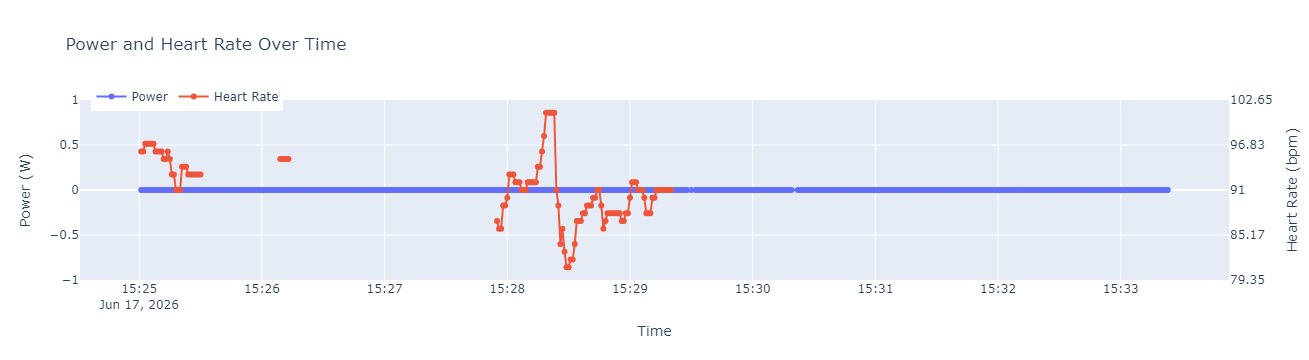

In [37]:
plot_power_and_heart_rate(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())

Von den drei gefundenen Lücken interpolieren wir die ersten beiden linear 
(Details siehe `missing_intervals`), da hier vor und nach der Lücke plausible 
Referenzwerte vorhanden sind. Die dritte Lücke bleibt NaN, da am Ende der 
Aufzeichnung kein Wert nach der Lücke existiert, der eine Interpolation erlauben würde.

In [38]:
missing_intervals = get_missing_intervals(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())

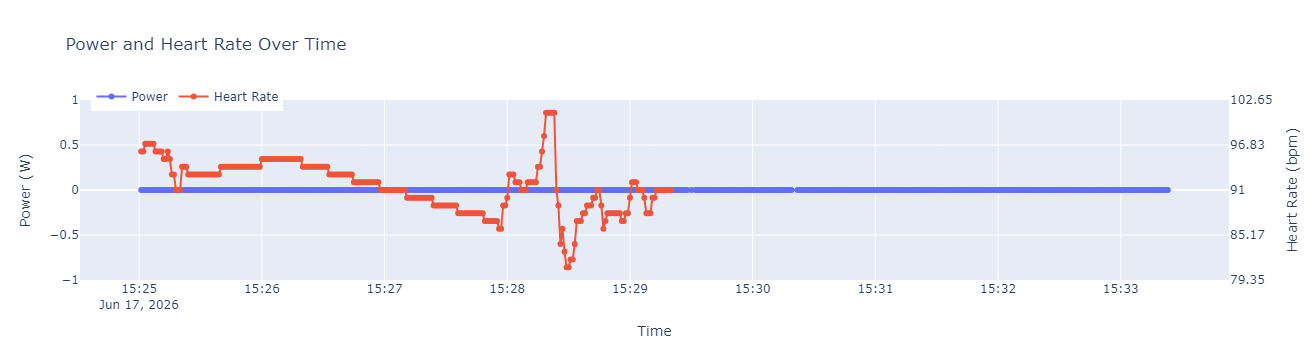

In [39]:
interpolate_range(df, missing_intervals.start[0], missing_intervals.end[1])
plot_power_and_heart_rate(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())

So, auf zur letzten Fahrt:

In [40]:
ride_with_missing_values = df.loc[(df.source_file == "2026-02-26-20-51-14.fit") & (df.heart_rate.isna()), ["heart_rate", "power"]]

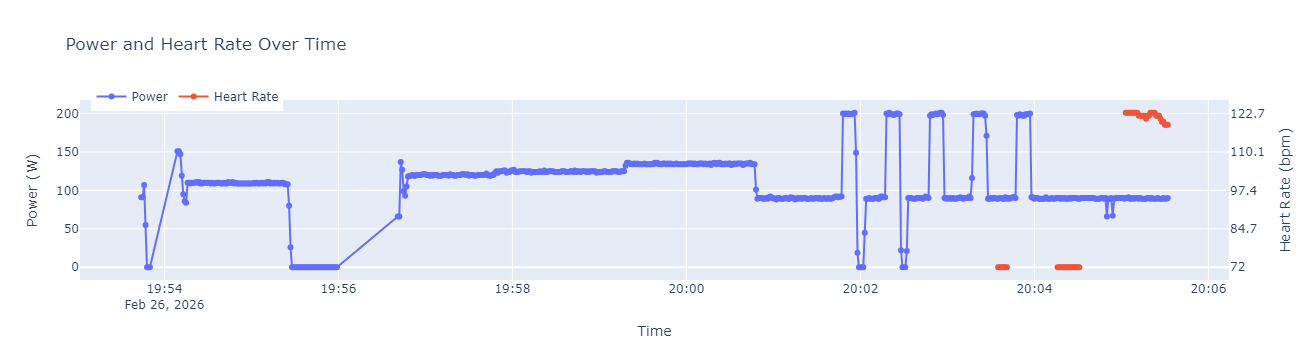

In [41]:
plot_power_and_heart_rate(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())

Bei allen bisherigen Fahrten war die getretene Leistung 0 oder gering. Mögliche Erklärung ist häufig, dass ich im Bad war und der Herzfrequenzmesser die Verbindung verloren hat. Hier hat eindeutig der Herzfrequenzmesser nicht funktioniert. In der ersten sehr großen Lücke gab es viele unterschiedliche Leistungen. In der zweiten gab es einen Leistungsspike. Daher will ich hier nicht annähern. Die dritte Lücke ist ein Jump von 50 bpm, ohne dass die Leistung widerspiegelt, warum das so sein könnte. Daher lasse ich auch hier die Werte NaN.
Schauen wir nochmal auf alle Fahrten mit teilweise fehlenden Werten:

In [42]:
summary = df.groupby("source_file")["heart_rate"].agg(
    total="size",
    nan_count=lambda x: x.isna().sum()
)
summary["nan_ratio"] = summary["nan_count"] / summary["total"]

summary[(summary.nan_ratio > 0) & (summary.nan_ratio < 1)]

,total,nan_count,nan_ratio
source_file,,,
2026-02-26-20-51-14.fit,3310,597,0.180363
2026-06-03-15-30-13.fit,7005,7,0.000999
2026-06-17-15-49-01.fit,6080,239,0.039309
2026-08-27-19-58-44.fit,2769,6,0.002167
2026-09-20-14-01-24.fit,7454,12,0.001610


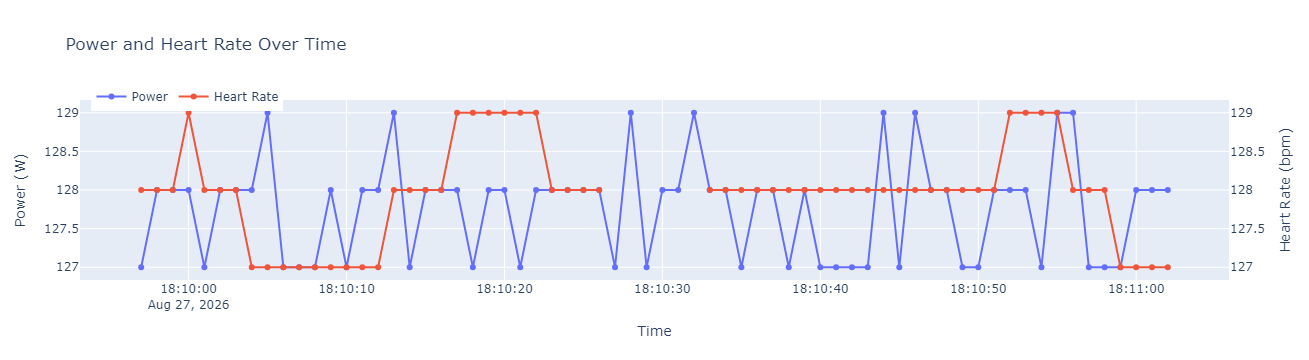

In [45]:
ride_with_missing_values = df.loc[(df.source_file == "2026-08-27-19-58-44.fit") & (df.heart_rate.isna()), ["heart_rate", "power"]]
plot_power_and_heart_rate(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())

Hier ist das fehlende Intervall klein genug und die Powerwerte nah genug aneinander. Daher interpolieren wir linear.

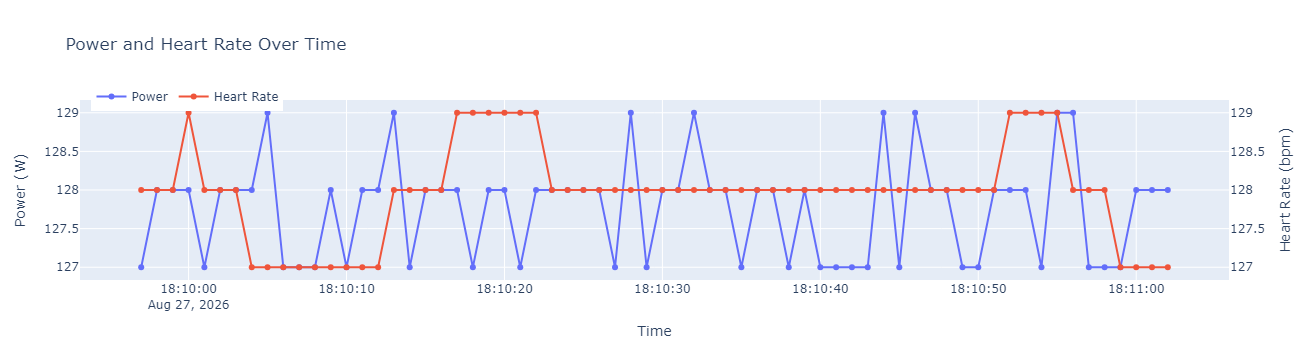

In [46]:
df = interpolate_range(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())
plot_power_and_heart_rate(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())

In [47]:
summary = df.groupby("source_file")["heart_rate"].agg(
    total="size",
    nan_count=lambda x: x.isna().sum()
)
summary["nan_ratio"] = summary["nan_count"] / summary["total"]

summary[(summary.nan_ratio > 0) & (summary.nan_ratio < 1)]

,total,nan_count,nan_ratio
source_file,,,
2026-02-26-20-51-14.fit,3310,597,0.180363
2026-06-03-15-30-13.fit,7005,7,0.000999
2026-06-17-15-49-01.fit,6080,239,0.039309
2026-09-20-14-01-24.fit,7454,12,0.001610


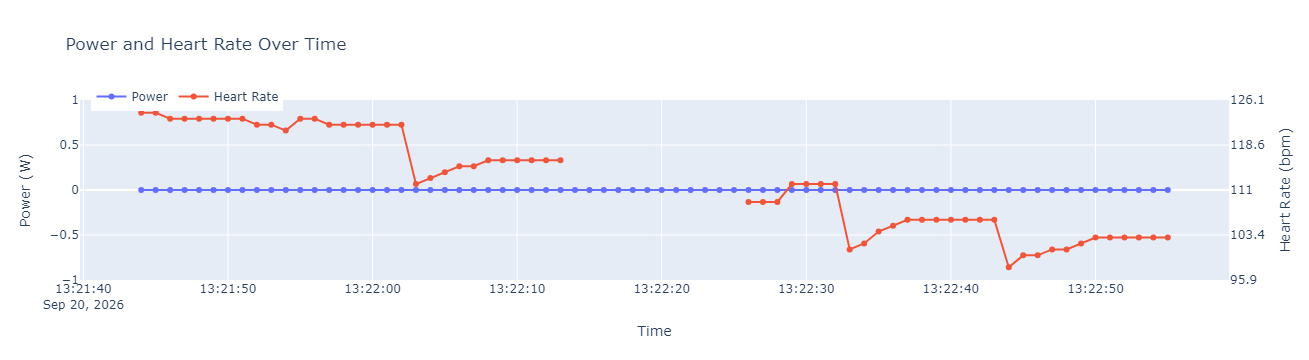

In [48]:
ride_with_missing_values = df.loc[(df.source_file == "2026-09-20-14-01-24.fit") & (df.heart_rate.isna()), ["heart_rate", "power"]]
plot_power_and_heart_rate(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())

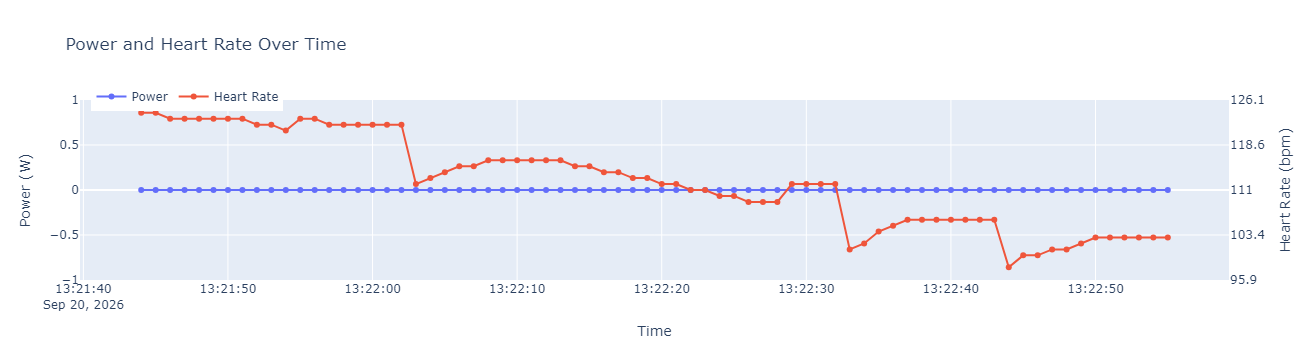

In [49]:
df = interpolate_range(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())
plot_power_and_heart_rate(df, ride_with_missing_values.index.min(), ride_with_missing_values.index.max())

In [50]:
summary = df.groupby("source_file")["heart_rate"].agg(
    total="size",
    nan_count=lambda x: x.isna().sum()
)
summary["nan_ratio"] = summary["nan_count"] / summary["total"]

summary[(summary.nan_ratio > 0) & (summary.nan_ratio < 1)]

,total,nan_count,nan_ratio
source_file,,,
2026-02-26-20-51-14.fit,3310,597,0.180363
2026-06-03-15-30-13.fit,7005,7,0.000999
2026-06-17-15-49-01.fit,6080,239,0.039309


In [51]:
df.to_csv("./Dataframes/processed_data.csv")

## Zusammenfassung

- Fahrten mit 100% fehlenden Herzfrequenzwerten wurden unverändert gelassen 
  (kein Sensor verbunden)
- Kurze Lücken (wenige Sekunden bis ~1 Minute) bei niedriger/keiner Leistung 
  wurden linear interpoliert, da in diesem Kontext kein starker 
  Herzfrequenzanstieg zu erwarten ist
- Längere Lücken oder Lücken mit auffälligen Leistungssprüngen bzw. 
  unerklärlichen Herzfrequenz-Sprüngen danach wurden bewusst als NaN belassen, 
  um keine falschen Werte zu erzeugen
- Das bereinigte DataFrame wird als `processed_data.csv` gespeichert und dient 
  als Grundlage für die weitere Analyse